In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from fomoz.color_selection import (
    Measure,
    Optimize,
    SelectBackground
)

In [2]:
# Load the reference sample, having the entries
# 'g', 'r', 'i', 'redshift'
ref_sample = pd.read_csv('./../data/input/reference.csv', comment='#')

# Define the z_l points and bands
# used for the calibration of the selection
z_l = [0.3, 0.4, 0.5, 0.6, 0.7]
bands = ['g', 'r', 'i']

# c_i and s_i samples
c_precision = 0.01
s_samples = np.linspace(0.3, 1.7, 30)

# Measure C, P, and F for all color conditions
measure = Measure(
    ref_sample, bands, z_l,
    c_precision=c_precision,
    s_samples=s_samples,
    z_gal_string='redshift',  # redshift string
    missing_data=-99,  # non-detection value
)
measure.process(cpu_number=None)

Computing color cuts given the following set of bands: ['g', 'r', 'i']


Processing all z_l points for the color (r-i): 100%|██████████| 5/5 [00:00<00:00, 99.81it/s]



Running iterative purity threshold search...

Combining the final optimal cuts across redshift bins...
Iterative thresholding complete. Total time: 2.01 seconds.

Completeness: [0.80128738 0.79390325 0.81340835 0.7865225  0.49120357]
Purity: [0.97032939 0.97082658 0.97144457 0.97052436 0.97075055]
Foreground failure rate: [0.28502415 0.15384615 0.10580913 0.07581804 0.03214069]


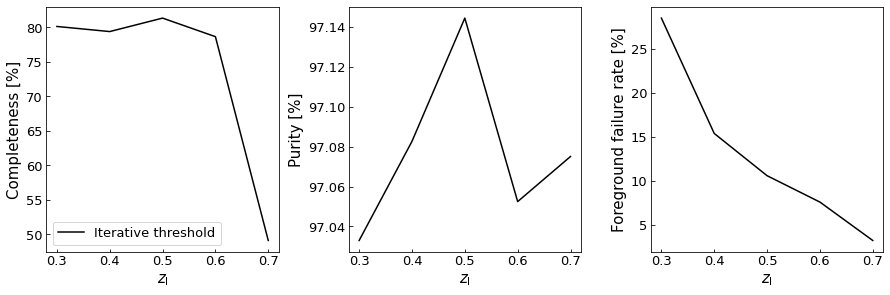

In [3]:
# Get the optimal combination of color conditions
P_min = 0.97  # global purity threshold

optim = Optimize(measure)
optim.process(
    P_min,
    start_purity=0.999,
    step=0.0001
)

# Plot the global completeness, purity,
# and foreground failure rate
optim.plot(loclegend='lower left')

In [4]:
# Load the test sample
# (it's the reference sample in this example)
test_sample = ref_sample

# New test z_l points
zl_new = np.arange(min(z_l), max(z_l), 0.005)

# SelectBackground instance, taking
# the Optimize object in input. Alternatively,
# the file written with write_optimal_selection()
# can be provided in input
sel = SelectBackground()
sel.load_parameters(optim)

# Galaxy selection.
# mask is a list of boolean arrays.
# The i-th array corresponds to zl_new[i].
sel.process(zl_new, test_sample)
mask = sel.mask

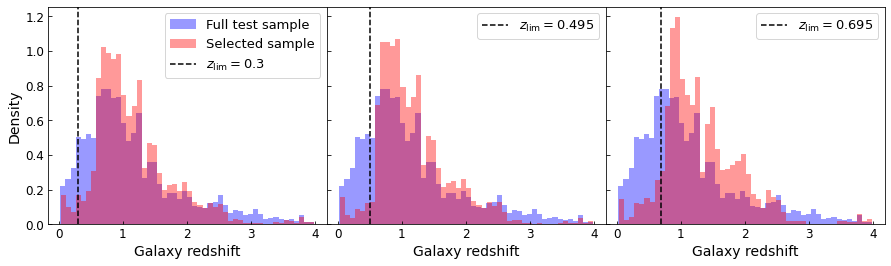

In [5]:
# Plot the redshift distributions for three values in zl_new
zl_new_index = [0, int(0.5 * (len(zl_new)-1)), len(zl_new) - 1]

fig, ax = plt.subplots(1, 3, figsize=(15,4), gridspec_kw={'wspace':0}, sharey='all')
ax[0].set_ylabel('Density', fontsize=14)

for i, axis in enumerate(ax):

    axis.tick_params(which='both', direction='in', labelsize=12)
    axis.set_xlabel('Galaxy redshift', fontsize=14)

    axis.hist(
        test_sample['redshift'],
        bins=50, density=True, color='b', alpha=0.4, label='Full test sample' if axis==ax[0] else None
    )

    axis.hist(
        test_sample[mask[zl_new_index[i]]]['redshift'],
        bins=50, density=True, color='r', alpha=0.4, label='Selected sample' if axis==ax[0] else None
    )

    axis.axvline(
        zl_new[zl_new_index[i]],
        color='k', linestyle='--', label=r"$z_{\rm lim}="+f"{round(zl_new[zl_new_index[i]],3)}$"
    )

    axis.legend(loc='upper right', fontsize=13)

plt.show()